TIME SERIES DATA
                 Sales
Date                  
2020-01-01  102.483571
2020-02-01  111.308678
2020-03-01  124.558951
2020-04-01  133.615149
2020-05-01  124.149741


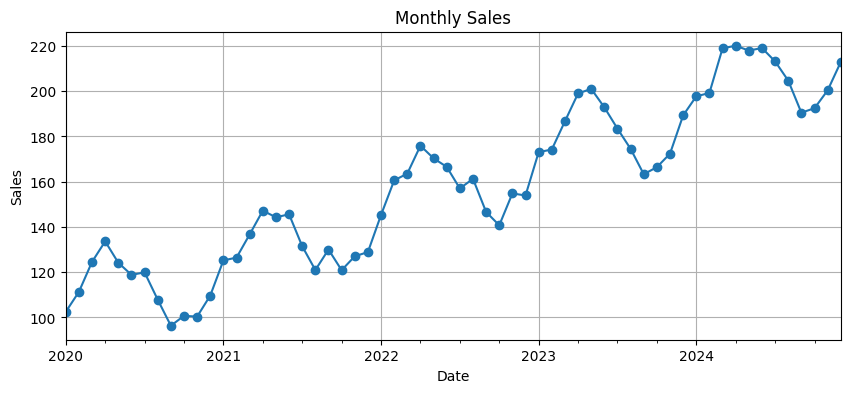

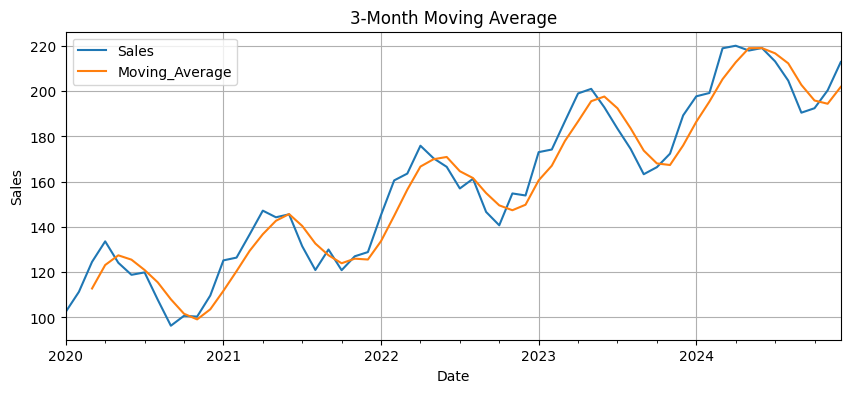

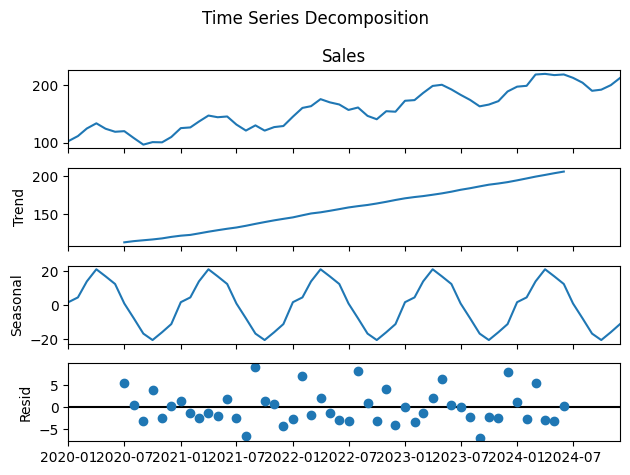


ADF TEST
ADF Statistic: 1.1901260750369893
p-value: 0.9959169486856854
Non-stationary


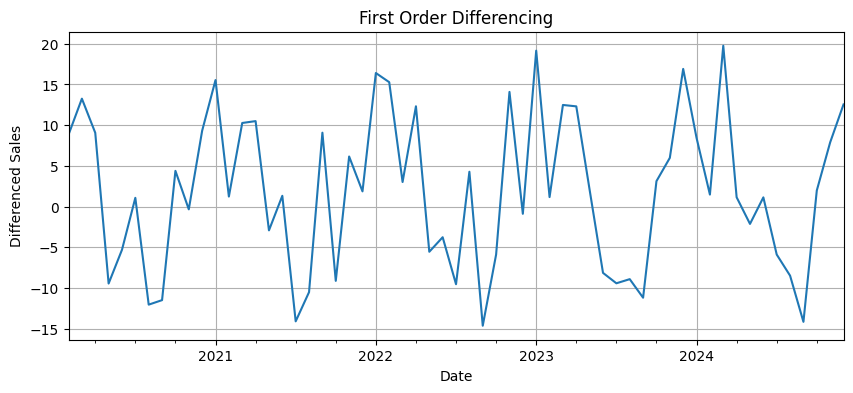


ADF TEST AFTER DIFFERENCING
ADF Statistic: -7.491611489643968
p-value: 4.490109821123952e-11
Stationary


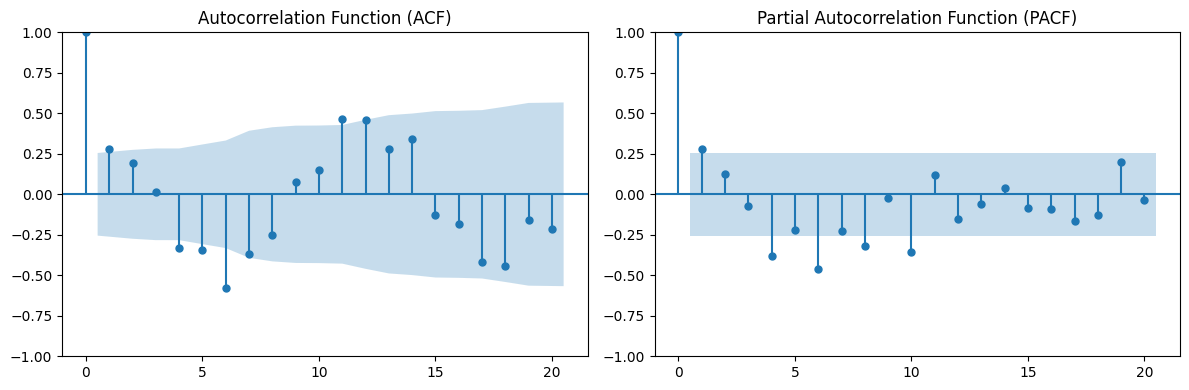


Training Samples: 48
Testing Samples: 12

ARIMA MODEL SUMMARY
                               SARIMAX Results                                
Dep. Variable:                  Sales   No. Observations:                   48
Model:                 ARIMA(1, 1, 1)   Log Likelihood                -171.550
Date:                Tue, 17 Nov 2026   AIC                            349.100
Time:                        17:28:15   BIC                            354.651
Sample:                    01-01-2020   HQIC                           351.189
                         - 12-01-2023                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.4971      0.445      1.118      0.264      -0.374       1.369
ma.L1         -0.2175      0.523     -0.416      0.677      -1.242  

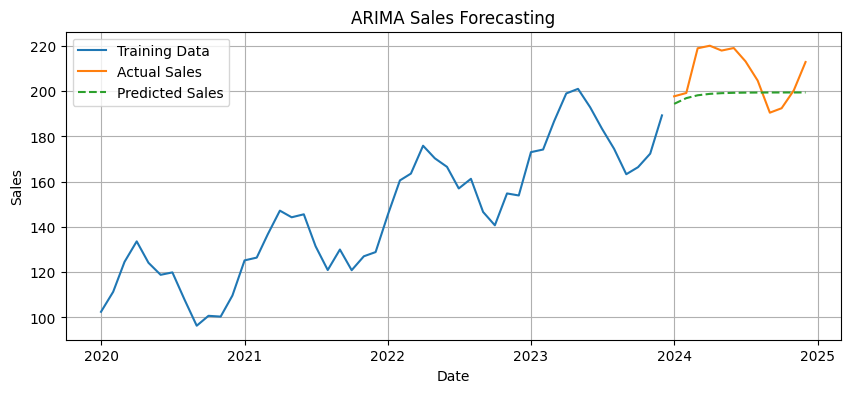


FORECASTING ACCURACY
MAE: 11.3
MSE: 181.27
RMSE: 13.46
MAPE: 5.32 %

NEXT 12 MONTHS FORECAST
            Forecasted_Sales
2025-01-01        217.076074
2025-02-01        219.162075
2025-03-01        220.198530
2025-04-01        220.713506
2025-05-01        220.969377
2025-06-01        221.096511
2025-07-01        221.159678
2025-08-01        221.191064
2025-09-01        221.206658
2025-10-01        221.214406
2025-11-01        221.218256
2025-12-01        221.220169


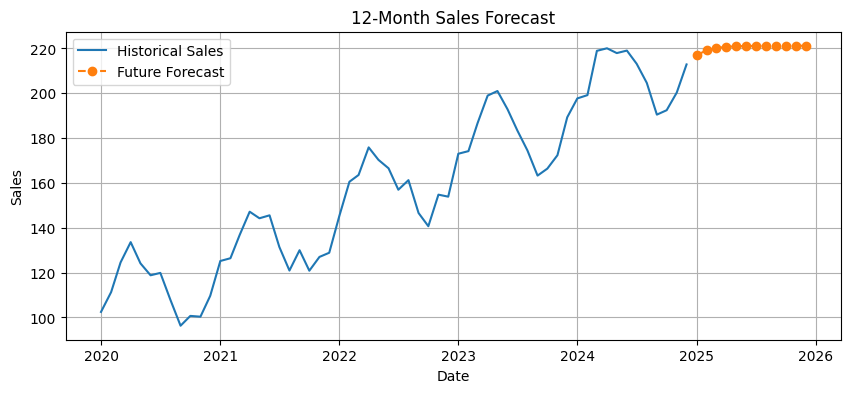

In [1]:
# Install libraries (run once in Google Colab)
!pip install -q pandas numpy matplotlib statsmodels scikit-learn

# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")

# STEP 1: Create Sample Time Series Dataset
np.random.seed(42)

dates = pd.date_range("2020-01-01", periods=60, freq="MS")
trend = np.arange(60) * 2
seasonality = 20 * np.sin(2 * np.pi * np.arange(60) / 12)
noise = np.random.normal(0, 5, 60)

df = pd.DataFrame(
    {"Sales": 100 + trend + seasonality + noise},
    index=dates
)
df.index.name = "Date"

print("TIME SERIES DATA")
print(df.head())

# STEP 2: Visualize Time Series
df["Sales"].plot(figsize=(10, 4), marker="o", title="Monthly Sales")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.grid()
plt.show()

# STEP 3: Calculate Moving Average
df["Moving_Average"] = df["Sales"].rolling(3).mean()

df[["Sales", "Moving_Average"]].plot(
    figsize=(10, 4), title="3-Month Moving Average"
)
plt.ylabel("Sales")
plt.grid()
plt.show()

# STEP 4: Time Series Decomposition
decomposition = seasonal_decompose(df["Sales"], model="additive", period=12)
decomposition.plot()
plt.suptitle("Time Series Decomposition")
plt.tight_layout()
plt.show()

# STEP 5: Check Stationarity Using ADF Test
def check_stationarity(data, title):
    result = adfuller(data)
    print(f"\n{title}")
    print("ADF Statistic:", result[0])
    print("p-value:", result[1])
    print("Stationary" if result[1] < 0.05 else "Non-stationary")

check_stationarity(df["Sales"], "ADF TEST")

# STEP 6: First Order Differencing
diff_data = df["Sales"].diff().dropna()

diff_data.plot(figsize=(10, 4), title="First Order Differencing")
plt.ylabel("Differenced Sales")
plt.grid()
plt.show()

# STEP 7: ADF Test After Differencing
check_stationarity(diff_data, "ADF TEST AFTER DIFFERENCING")

# STEP 8: Plot ACF and PACF
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

plot_acf(diff_data, lags=20, ax=axes[0])
plot_pacf(diff_data, lags=20, method="ywm", ax=axes[1])

axes[0].set_title("Autocorrelation Function (ACF)")
axes[1].set_title("Partial Autocorrelation Function (PACF)")

plt.tight_layout()
plt.show()

# STEP 9: Split Dataset into Training and Testing
train_size = int(len(df) * 0.8)
train = df["Sales"].iloc[:train_size]
test = df["Sales"].iloc[train_size:]

print("\nTraining Samples:", len(train))
print("Testing Samples:", len(test))

# STEP 10: Build and Train ARIMA Model
model = ARIMA(train, order=(1, 1, 1))
model_fit = model.fit()

print("\nARIMA MODEL SUMMARY")
print(model_fit.summary())

# STEP 11: Forecast Test Data
forecast = model_fit.forecast(steps=len(test))

plt.figure(figsize=(10, 4))
plt.plot(train, label="Training Data")
plt.plot(test, label="Actual Sales")
plt.plot(test.index, forecast, "--", label="Predicted Sales")
plt.title("ARIMA Sales Forecasting")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.grid()
plt.show()

# STEP 12: Evaluate Forecasting Accuracy
mae = mean_absolute_error(test, forecast)
mse = mean_squared_error(test, forecast)
rmse = np.sqrt(mse)
mape = np.mean(np.abs((test - forecast) / test)) * 100

print("\nFORECASTING ACCURACY")
print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("MAPE:", round(mape, 2), "%")

# STEP 13: Forecast Next 12 Months
final_model = ARIMA(df["Sales"], order=(1, 1, 1)).fit()
future_forecast = final_model.forecast(steps=12)

future_dates = pd.date_range(
    start=df.index[-1] + pd.offsets.MonthBegin(1),
    periods=12,
    freq="MS"
)

future_df = pd.DataFrame(
    {"Forecasted_Sales": future_forecast.values},
    index=future_dates
)

print("\nNEXT 12 MONTHS FORECAST")
print(future_df)

# STEP 14: Visualize Future Forecast
plt.figure(figsize=(10, 4))
plt.plot(df["Sales"], label="Historical Sales")
plt.plot(
    future_df["Forecasted_Sales"],
    "--o",
    label="Future Forecast"
)
plt.title("12-Month Sales Forecast")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.grid()
plt.show()